In [5]:
import numpy as np
import pandas as pd

In [6]:
df = pd.read_csv("csv/cars_clus.csv")
df

,manufact,model,sales,resale,type,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,lnsales,partition
0,Acura,Integra,16.919,16.360,0.000,21.500,1.800,140.000,101.200,67.300,172.400,2.639,13.200,28.000,2.828,0.0
1,Acura,TL,39.384,19.875,0.000,28.400,3.200,225.000,108.100,70.300,192.900,3.517,17.200,25.000,3.673,0.0
2,Acura,CL,14.114,18.225,0.000,$null$,3.200,225.000,106.900,70.600,192.000,3.470,17.200,26.000,2.647,0.0
3,Acura,RL,8.588,29.725,0.000,42.000,3.500,210.000,114.600,71.400,196.600,3.850,18.000,22.000,2.150,0.0
4,Audi,A4,20.397,22.255,0.000,23.990,1.800,150.000,102.600,68.200,178.000,2.998,16.400,27.000,3.015,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154,Volvo,V70,17.531,$null$,0.000,28.800,2.400,168.000,104.900,69.300,186.200,3.259,17.900,25.000,2.864,0.0
155,Volvo,C70,3.493,$null$,0.000,45.500,2.300,236.000,104.900,71.500,185.700,3.601,18.500,23.000,1.251,0.0
156,Volvo,S80,18.969,$null$,0.000,36.000,2.900,201.000,109.900,72.100,189.800,3.600,21.100,24.000,2.943,0.0
157,NaN,newCar,$null$,$null$,$null$,21.500,1.500,76.000,106.300,67.900,175.000,2.932,11.900,46.000,$null$,1.0


In [7]:
df[[ 'sales', 'resale', 'type', 'price', 'engine_s',
       'horsepow', 'wheelbas', 'width', 'length', 'curb_wgt', 'fuel_cap',
       'mpg', 'lnsales']] = df[[ 'sales', 'resale', 'type', 'price', 'engine_s',
       'horsepow', 'wheelbas', 'width', 'length', 'curb_wgt', 'fuel_cap',
       'mpg', 'lnsales']].apply(pd.to_numeric, errors="coerce")
df = df.dropna()
df= df.reset_index(drop=True)
df

,manufact,model,sales,resale,type,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,lnsales,partition
0,Acura,Integra,16.919,16.360,0.0,21.50,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2.828,0.0
1,Acura,TL,39.384,19.875,0.0,28.40,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,3.673,0.0
2,Acura,RL,8.588,29.725,0.0,42.00,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,2.150,0.0
3,Audi,A4,20.397,22.255,0.0,23.99,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,3.015,0.0
4,Audi,A6,18.780,23.555,0.0,33.95,2.8,200.0,108.7,76.1,192.0,3.561,18.5,22.0,2.933,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,Volkswagen,Golf,9.761,11.425,0.0,14.90,2.0,115.0,98.9,68.3,163.3,2.767,14.5,26.0,2.278,0.0
113,Volkswagen,Jetta,83.721,13.240,0.0,16.70,2.0,115.0,98.9,68.3,172.3,2.853,14.5,26.0,4.427,0.0
114,Volkswagen,Passat,51.102,16.725,0.0,21.20,1.8,150.0,106.4,68.5,184.1,3.043,16.4,27.0,3.934,0.0
115,Volkswagen,Cabrio,9.569,16.575,0.0,19.99,2.0,115.0,97.4,66.7,160.4,3.079,13.7,26.0,2.259,0.0


In [8]:
df.columns
x = df[['sales', 'resale', 'type', 'price', 'engine_s',
       'horsepow', 'wheelbas', 'width', 'length', 'curb_wgt', 'fuel_cap',
       'mpg', 'lnsales']].values
x = x.astype(int)

In [9]:
from sklearn.preprocessing import MinMaxScaler
x_mms = MinMaxScaler().fit_transform(x)
x_mms

array([[0.02962963, 0.17741935, 0.        , ..., 0.13636364, 0.43333333,
        0.5       ],
       [0.07222222, 0.22580645, 0.        , ..., 0.31818182, 0.33333333,
        0.625     ],
       [0.01481481, 0.38709677, 0.        , ..., 0.36363636, 0.23333333,
        0.5       ],
       ...,
       [0.09444444, 0.17741935, 0.        , ..., 0.27272727, 0.4       ,
        0.625     ],
       [0.01666667, 0.17741935, 0.        , ..., 0.13636364, 0.36666667,
        0.5       ],
       [0.00925926, 0.12903226, 0.        , ..., 0.18181818, 0.36666667,
        0.375     ]], shape=(117, 13))

In [10]:
from sklearn.metrics.pairwise import euclidean_distances
ed = euclidean_distances(x_mms, x_mms)
ed

array([[0.        , 0.62280212, 0.7948337 , ..., 0.37887727, 0.35902461,
        0.27280343],
       [0.62280212, 0.        , 0.34429804, ..., 0.40414627, 0.68042083,
        0.69950871],
       [0.7948337 , 0.34429804, 0.        , ..., 0.61353156, 0.86278733,
        0.85839845],
       ...,
       [0.37887727, 0.40414627, 0.61353156, ..., 0.        , 0.47424806,
        0.5328049 ],
       [0.35902461, 0.68042083, 0.86278733, ..., 0.47424806, 0.        ,
        0.31504179],
       [0.27280343, 0.69950871, 0.85839845, ..., 0.5328049 , 0.31504179,
        0.        ]], shape=(117, 117))

C:\Users\ZAHRA\AppData\Local\Temp\ipykernel_15240\3583959164.py:5: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  Z_using_dist_matrix = hierarchy.linkage(ed, 'complete')


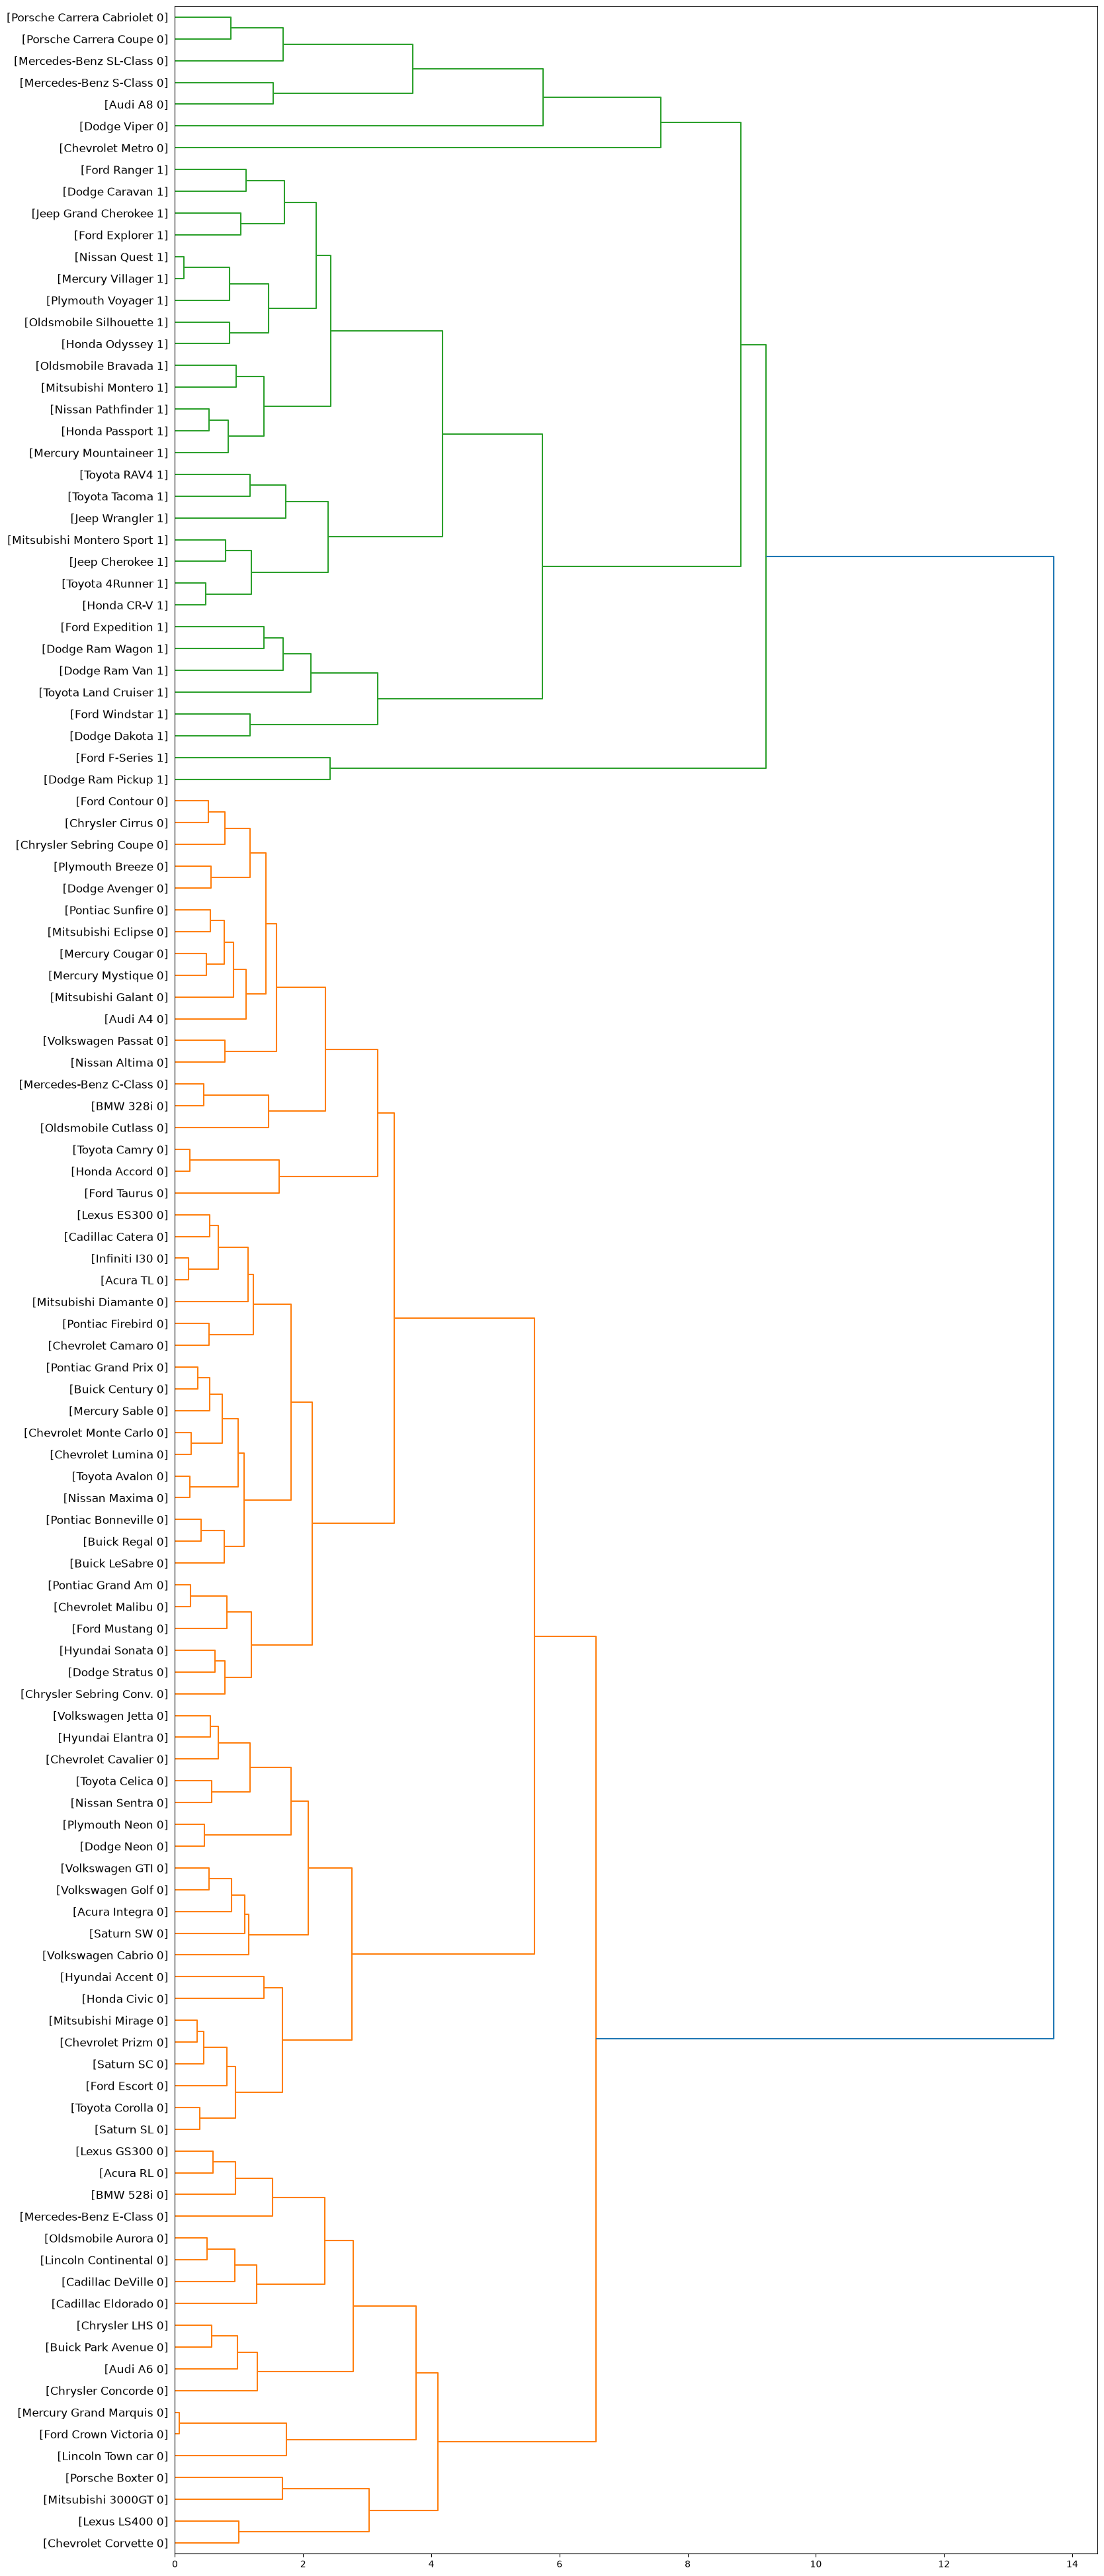

In [11]:
import matplotlib.pyplot as plt
import pylab
from scipy.cluster import hierarchy 

Z_using_dist_matrix = hierarchy.linkage(ed, 'complete')
fig = pylab.figure(figsize=(18,50))
def llf(id):
    return '[%s %s %s]' % (df['manufact'][id], df['model'][id], int(float(df['type'][id])) )
    
dendro = hierarchy.dendrogram(Z_using_dist_matrix,  leaf_label_func=llf, leaf_rotation=0, leaf_font_size =12, orientation = 'right')